# 🖼️ CIFAR-100 Deep Image Classification Pipeline

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sahilgoury7/genai-lab/blob/main/02_cifar100_cnn_pipeline/cifar100_project.ipynb)
[![GitHub](https://img.shields.io/badge/GitHub-genai--lab-181717?style=flat&logo=github&logoColor=white)](https://github.com/sahilgoury7/genai-lab)
[![LinkedIn](https://img.shields.io/badge/LinkedIn-Sahil%20Goury-0077B5?style=flat&logo=linkedin&logoColor=white)](https://www.linkedin.com/in/sahil-goury-269107370/)
[![TensorFlow](https://img.shields.io/badge/TensorFlow-2.x%20%2F%20Keras-FF6F00?style=flat&logo=tensorflow&logoColor=white)](https://www.tensorflow.org/)
[![Status](https://img.shields.io/badge/Status-Completed%20%E2%9C%85-success)](#)

📊 **Dataset:** [CIFAR-100 (50,000 Train / 10,000 Test across 100 classes)](https://www.cs.toronto.edu/~kriz/cifar.html)  
📓 **Repository:** [sahilgoury7/genai-lab](https://github.com/sahilgoury7/genai-lab)  
💼 **Author:** [Sahil Goury](https://www.linkedin.com/in/sahil-goury-269107370/)  

---

### Project Overview
An end-to-end Computer Vision project addressing the challenging **CIFAR-100** dataset (100 fine-grained real-world object categories).
This project contrasts a **naive Baseline CNN** suffering from severe overfitting (38% generalization gap) against an **Augmented & Regularized Pro CNN** that slashes test loss by 32% using:
- **Data Augmentation** (`RandomFlip`, `RandomRotation`, `RandomZoom`)
- **Batch Normalization** after each convolutional block
- **Adaptive Callbacks** (`EarlyStopping`, `ReduceLROnPlateau`)
- **Center-Crop Real-World Inference** on high-resolution internet images


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras import layers
from tensorflow.keras.layers import Dense, Flatten

In [2]:
import tensorflow as tf

# Load CIFAR-100 dataset
(cifar100_train, cifar100_test) = tf.keras.datasets.cifar100.load_data()

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 1999s 12us/step


In [3]:
# Unpack the dataset
(x_train, y_train), (x_test, y_test) = cifar100_train, cifar100_test

In [4]:
print("X_train shape:", x_train.shape)
print("X_test shape:", x_test.shape)
print("Sample label:", y_train[0])

X_train shape: (50000, 32, 32, 3)
X_test shape: (10000, 32, 32, 3)
Sample label: [19]


Check and Visualize Data
Displaying a few sample images along with their labels to verify that the dataset loaded correctly.

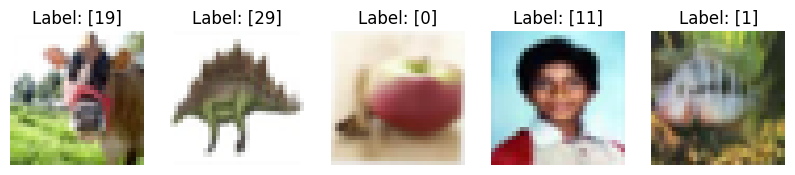

In [5]:
# 1 row aur 5 columns mein 5 image boxes (subplots) banao
# figsize=(10, 3) → poore figure ki width 10 aur height 3 rakho
fig, axes = plt.subplots(1, 5, figsize=(10, 3))


# 0 se 4 tak loop chalega → total 5 images
for i in range(5):

    # x_train ki i-th image ko i-th box mein display karo
    # x_train[i] → ek image
    # imshow() → image ko screen par dikhata hai
    axes[i].imshow(x_train[i], cmap='gray')

    # image ke upar us image ka label/class number likho
    # y_train[i] → i-th image ka label
    axes[i].set_title(f"Label: {y_train[i]}")

    # image ke x-axis aur y-axis ko hide karo
    axes[i].axis('off')


# Finally, saari 5 images ko screen par show karo
plt.show()

In [6]:
x_train = x_train / 255.0
x_test = x_test / 255.0

5. Build Model Architecture

The `NameError` indicates that the `model` was not defined. This typically happens if the cell where the model is built was not executed. I will re-add the model architecture definition and the compilation step here to ensure it's properly set up.

In [7]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    # --- Block 1: Edges & Textures detect karna ---
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # --- Block 2: Shapes aur Parts detect karna ---
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # --- Block 3: Complex Objects detect karna ---
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # --- Classifier Head (Jo aapne seekha tha) ---
    layers.Flatten(),                                # 3D features ko 1D vector me badlo
    layers.Dense(256, activation='relu'),            # Hidden Dense Layer
    layers.Dropout(0.5),                             # Overfitting rokne ke liye
    layers.Dense(100, activation='softmax')          # 100 Output Neurons (100 Classes ke liye)
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        25,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 644,388 (2.46 MB)

 Trainable params: 643,940 (2.46 MB)

 Non-trainable params: 448 (1.75 KB)

MODEL KO TRAINING KE LIYE READY KARO


In [8]:
# optimizer = Adam → weights/biases ko update karega
# loss = Sparse Categorical Crossentropy → prediction ki galti measure karega
# accuracy → kitni predictions correct hain, batayega

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [10]:
# x_train → training images dega
# y_train → correct labels dega
# epochs=10 → model ko data 10 baar train karayega
# validation_split=0.2 → 20% data se model ki performance check karega
# history → training ka result save karega

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2
)


Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.1108 - loss: 3.7640 - val_accuracy: 0.1911 - val_loss: 3.3525
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.1399 - loss: 3.5881 - val_accuracy: 0.2104 - val_loss: 3.2522
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.1694 - loss: 3.4016 - val_accuracy: 0.2505 - val_loss: 3.0660
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.2070 - loss: 3.2102 - val_accuracy: 0.2726 - val_loss: 2.9289
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.2394 - loss: 3.0345 - val_accuracy: 0.3248 - val_loss: 2.6857
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.2742 - loss: 2.8563 - val_accuracy: 0.3136 - val_loss: 2.7188
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.3141 - loss: 2.6704 - val_accuracy: 0.3551 - val_loss: 2.5353
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.3480 - loss: 2.5012 -

In [11]:
#model.evaluate() (Keras ka in-built checker): Yeh tab kaam karta hai jab pura model
# aur test data Keras ke andar hi ho

test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Final Test Accuracy: {test_acc * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4014 - loss: 2.3337
Final Test Accuracy: 40.14%


In [12]:
#y_prob: Har photo ke liye 100 classes ki probability (Shape: 10000, 100).
#Har photo ki row me se sabse badi probability wali
# class ka Index number nikaalna (Shape: 10000).

y_prob = model.predict(x_test)
y_pred = y_prob.argmax(axis=1)

# Sample prediction check
print("Predicted digit:", y_pred[0])
print("Actual digit:   ", y_test[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Predicted digit: 95
Actual digit:    [49]


accuracy_score(y_test, y_pred): Asli labels (y_test) aur model ke predicted labels (y_pred) ko aapas me match karke final percentage accuracy nikaalta hai.

sklearn.metrics.accuracy_score (Data Science ka Standard Tool): Yeh Scikit-Learn library ka function hai. Jab aapke paas ek baar y_pred (predictions) haath me aa jaate hain, toh aap sklearn se aur bhi advanced cheezein nikaal sakte ho, jaise:
Confusion Matrix (Model kis class me sabse zyada confuse ho raha hai — jaise billi ko kutta samajh raha hai ya car ko bus).
Classification Report (Har 100 classes ka alag-alag precision aur recall).

In [13]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.4014

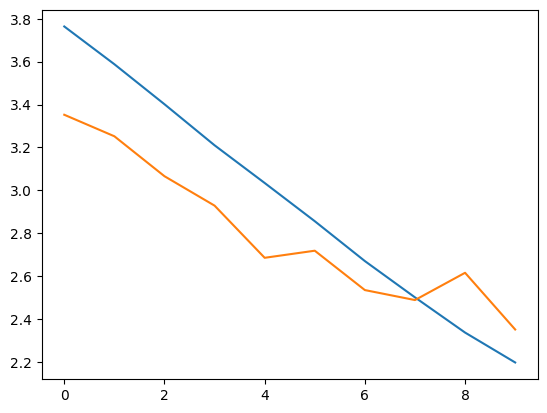

In [14]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

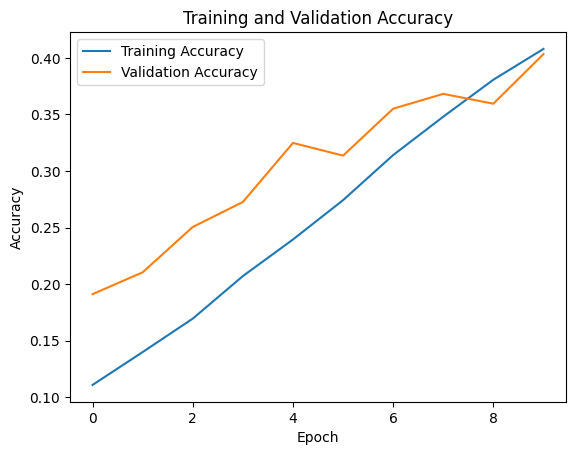

In [15]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

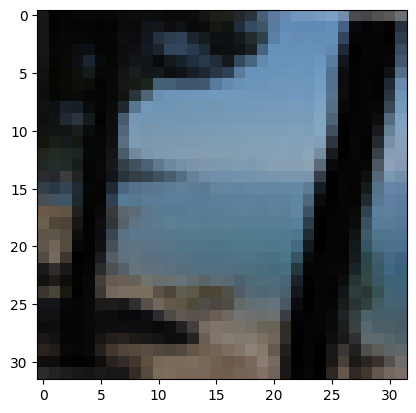

In [16]:
import matplotlib.pyplot as plt # Import plotting library
plt.imshow(x_test[10]) # Display the image at index 10 of the test set

In [17]:
model.predict(x_test[10].reshape(1, 32, 32, 3)).argmax(axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 637ms/step


array([87])

In [18]:
# CIFAR-100 ke 100 Fine Classes ke naam
cifar100_labels = [
    'apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle',
    'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel',
    'can', 'castle', 'caterpillar', 'cattle', 'chair', 'chimpanzee', 'clock',
    'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur',
    'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster',
    'house', 'kangaroo', 'keyboard', 'lamp', 'lawn_mower', 'leopard', 'lion',
    'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain', 'mouse',
    'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree', 'pear',
    'pickup_truck', 'pine_tree', 'plain', 'plate', 'poppy', 'porcupine',
    'possum', 'rabbit', 'raccoon', 'ray', 'road', 'rocket', 'rose', 'sea',
    'seal', 'shark', 'shrew', 'skunk', 'skyscraper', 'snail', 'snake', 'spider',
    'squirrel', 'streetcar', 'sunflower', 'sweet_pepper', 'table', 'tank',
    'telephone', 'television', 'tiger', 'tractor', 'train', 'trout', 'tulip',
    'turtle', 'wardrobe', 'whale', 'willow_tree', 'wolf', 'woman', 'worm'
]

true_class_id = y_test[10][0]
predicted_class_id = 87

print(f"🎯 Asli Sach (Ground Truth) : Class {true_class_id} -> '{cifar100_labels[true_class_id]}'")
print(f"🤖 Model Ka Guess           : Class {predicted_class_id} -> '{cifar100_labels[predicted_class_id]}'")

if true_class_id == predicted_class_id:
    print("\n🎉 Sahi Pehchana! Model Pass!")
else:
    print("\n❌ Galat Guess! Model Fail!")


🎯 Asli Sach (Ground Truth) : Class 71 -> 'sea'
🤖 Model Ka Guess           : Class 87 -> 'television'

❌ Galat Guess! Model Fail!


In [19]:



# Image 10 ki 100 classes ki probabilities
sample_probs = model.predict(x_test[10:11])[0]

# Top 5 sabse badi probabilities ke indices nikalte hain
top5_indices = np.argsort(sample_probs)[-5:][::-1]

print("🏆 Model Ke Top 5 Guesses:")
for rank, idx in enumerate(top5_indices, 1):
    print(f"#{rank}: {cifar100_labels[idx]} -> {sample_probs[idx]*100:.2f}%")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
🏆 Model Ke Top 5 Guesses:
#1: television -> 73.70%
#2: ray -> 9.34%
#3: shark -> 2.82%
#4: skyscraper -> 1.67%
#5: worm -> 1.48%


In [20]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Data Augmentation Pipeline
data_augmentation = keras.Sequential([
    # 1. Horizontal Flip (Mirror Image)
    layers.RandomFlip("horizontal"),

    # 2. Random Rotation (Halka sa 10% ghumaana)
    layers.RandomRotation(0.1),

    # 3. Random Zoom (Halka sa 10% zoom in / zoom out)
    layers.RandomZoom(0.1),
], name="data_augmentation")


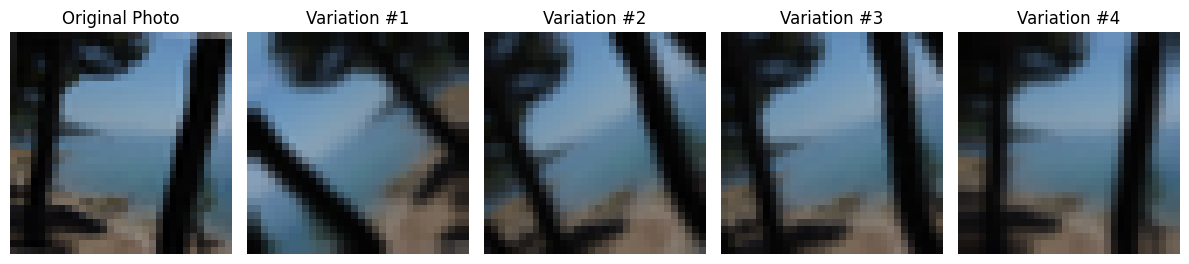

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Image 10 ko lete hain
sample_img = x_test[10]

plt.figure(figsize=(12, 3))

# 1. Original photo
plt.subplot(1, 5, 1)
plt.imshow(sample_img)
plt.title("Original Photo")
plt.axis("off")

# 2. 4 alag-alag Augmented variations
for i in range(4):
    # Pipeline se naya variation banate hain
    augmented_img = data_augmentation(sample_img[tf.newaxis, ...])

    plt.subplot(1, 5, i + 2)
    # Clip lagaya taaki values 0.0 se 1.0 ke beech hi rahein
    plt.imshow(np.clip(augmented_img[0].numpy(), 0.0, 1.0))
    plt.title(f"Variation #{i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


Augmentation Ko Model Me Kaise Fit Karein?

In [22]:
model_augmented = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # 🛡️ Step 1: Augmentation Layer (Sirf Training me chalegi, Testing me Keras khud band kar dega!)
    data_augmentation,

    # --- Block 1 ---
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # --- Block 2 ---
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # --- Block 3 ---
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # --- Classifier ---
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(100, activation='softmax')
], name="cifar100_pro_augmented_cnn")


Complete Model 2 Code: Build, Compile & Train

In [23]:
# 1. Model 2 Architecture (Augmentation ke sath)
model_2 = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # 🛡️ Data Augmentation Layer (Sirf Training me chalegi)
    data_augmentation,

    # --- Block 1: Edges ---
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # --- Block 2: Shapes ---
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # --- Block 3: Complex Objects ---
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # --- Classifier Head ---
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(100, activation='softmax')
], name="cifar100_model_2_augmented")

# 2. Model 2 Compile karna
model_2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Smart Callbacks Set karna
callbacks_list = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    )
]

print("✅ Model 2 Ready! Summary:")
model_2.summary()


✅ Model 2 Ready! Summary:


Model: "cifar100_model_2_augmented"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 100)            │        25,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 644,388 (2.46 MB)

 Trainable params: 643,940 (2.46 MB)

 Non-trainable params: 448 (1.75 KB)

Ab Training Start Karo (Epochs = 25):

In [26]:
# 4. Model 2 Training Start!
history_2 = model_2.fit(
    x_train,
    y_train,
    epochs=25,
    batch_size=64,
    validation_split=0.2,
    callbacks=callbacks_list # <-- Smart guards activate ho gaye!
)


Epoch 1/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 12ms/step - accuracy: 0.0540 - loss: 4.3095 - val_accuracy: 0.1164 - val_loss: 3.8732 - learning_rate: 0.0010
Epoch 2/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.0878 - loss: 3.9580 - val_accuracy: 0.1488 - val_loss: 3.6468 - learning_rate: 0.0010
Epoch 3/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.1120 - loss: 3.7871 - val_accuracy: 0.1374 - val_loss: 3.6027 - learning_rate: 0.0010
Epoch 4/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.1281 - loss: 3.6688 - val_accuracy: 0.1434 - val_loss: 3.5575 - learning_rate: 0.0010
Epoch 5/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.1489 - loss: 3.5644 - val_accuracy: 0.2175 - val_loss: 3.2032 - learning_rate: 0.0010
Epoch 6/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.1605 - loss: 3.4713 - val_accuracy: 0.2019 - val_loss: 3.2994 - learning_rate: 0.0010
Epoch 7/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.1757 - loss: 

Model 2 Ka Final Test Scoreboard:

In [27]:
test_loss_2, test_acc_2 = model_2.evaluate(x_test, y_test)
print(f"🏆 Model 2 Final Test Accuracy: {test_acc_2 * 100:.2f}%")
print(f"📉 Model 2 Final Test Loss    : {test_loss_2:.4f}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4393 - loss: 2.1498
🏆 Model 2 Final Test Accuracy: 43.93%
📉 Model 2 Final Test Loss    : 2.1498


 The Climax: Kya Image #10 par TV ka bhoot utra? 📺 vs 🌊

In [28]:
# Image 10 par Model 2 ka guess
sample_probs_2 = model_2.predict(x_test[10:11])[0]
top5_indices_2 = np.argsort(sample_probs_2)[-5:][::-1]

print("\n🏆 Model 2 Ke Top 5 Guesses for Image #10:")
for rank, idx in enumerate(top5_indices_2, 1):
    print(f"#{rank}: {cifar100_labels[idx]} -> {sample_probs_2[idx]*100:.2f}%")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step

🏆 Model 2 Ke Top 5 Guesses for Image #10:
#1: television -> 47.21%
#2: skyscraper -> 6.07%
#3: bridge -> 6.04%
#4: wardrobe -> 5.60%
#5: couch -> 5.21%


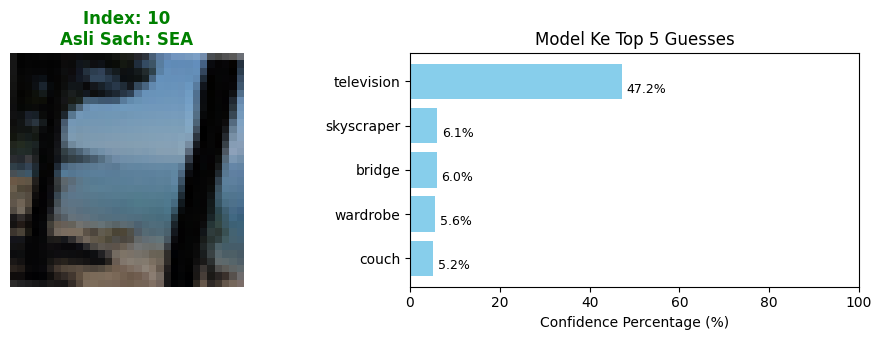

In [31]:
def inspect_image(image_index):
    img = x_test[image_index]
    true_label = cifar100_labels[y_test[image_index][0]]

    # Model 2 se prediction
    probs = model_2.predict(img.reshape(1, 32, 32, 3), verbose=0)[0]
    top5_idx = np.argsort(probs)[-5:]
    top5_labels = [cifar100_labels[i] for i in top5_idx]
    top5_values = probs[top5_idx] * 100

    plt.figure(figsize=(10, 3.5))

    # 1. Left side: Image
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title(f"Index: {image_index}\nAsli Sach: {true_label.upper()}", fontsize=12, fontweight='bold', color='green')
    plt.axis('off')

    # 2. Right side: Top 5 Bar Chart
    plt.subplot(1, 2, 2)
    bars = plt.barh(top5_labels, top5_values, color='skyblue')
    plt.xlabel('Confidence Percentage (%)')
    plt.title('Model Ke Top 5 Guesses', fontsize=12)
    plt.xlim(0, 100)
    for bar in bars:
        w = bar.get_width()
        plt.text(w + 1, bar.get_y() + 0.15, f"{w:.1f}%", fontsize=9)

    plt.tight_layout()
    plt.show()

# Index 10 ko dekhte hain (Samandar wali photo)
inspect_image(10)


/tmp/ipykernel_2680/3039393678.py:26: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2680/3039393678.py:26: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


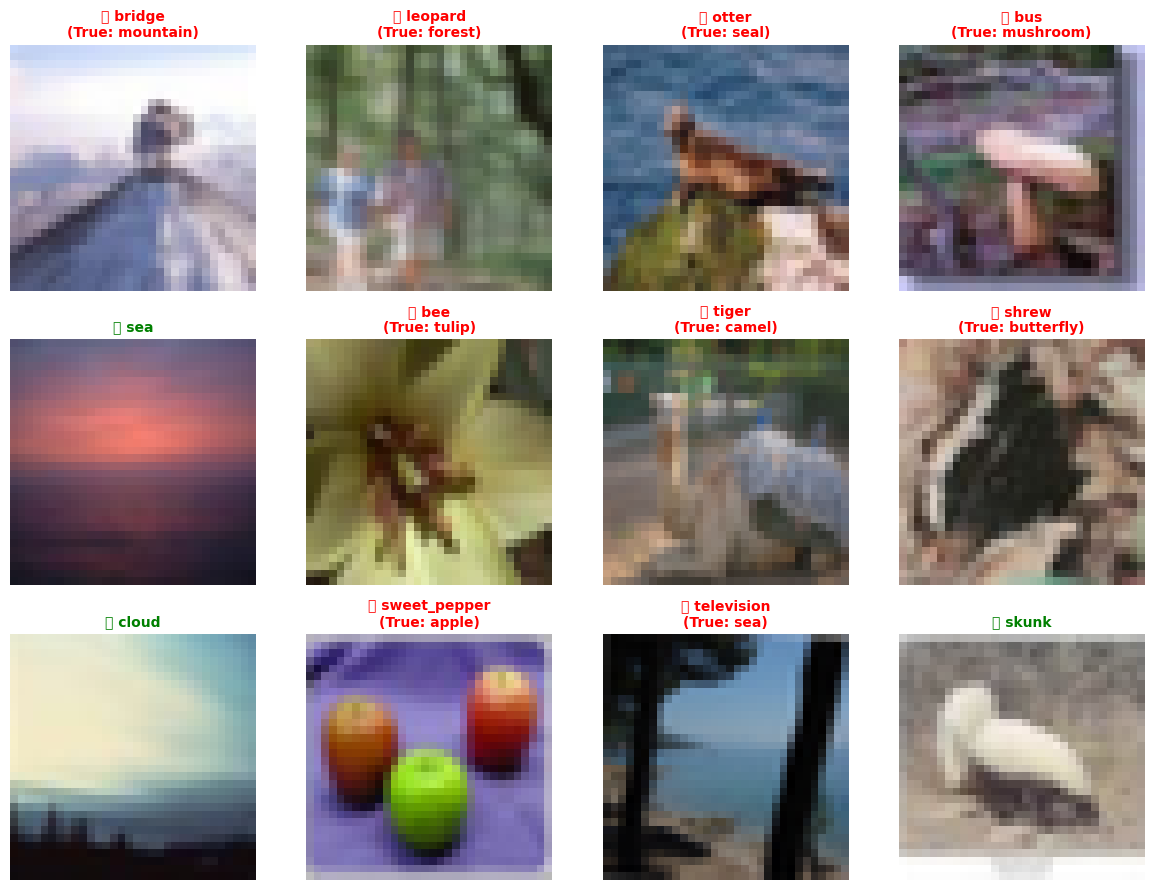

In [32]:
# 12 Random Test Photos Ka Grid
plt.figure(figsize=(12, 9))

for i in range(12):
    img = x_test[i]
    true_cls = cifar100_labels[y_test[i][0]]

    # Prediction
    pred_idx = model_2.predict(img.reshape(1, 32, 32, 3), verbose=0).argmax(axis=1)[0]
    pred_cls = cifar100_labels[pred_idx]

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)

    # Sahi hai ya galat check karte hain
    if pred_cls == true_cls:
        color = 'green'
        title = f"✅ {pred_cls}"
    else:
        color = 'red'
        title = f"❌ {pred_cls}\n(True: {true_cls})"

    plt.title(title, color=color, fontsize=10, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()


In [33]:
# Saari 10,000 test photos par probabilities nikaalte hain
y_pred_probs = model_2.predict(x_test, batch_size=64)

# Check karte hain ki kya asli answer top 5 guesses me tha
import tensorflow as tf

# Top-5 Accuracy calculate karna
top5_metric = tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5)
top5_metric.update_state(y_test, y_pred_probs)
top5_acc = top5_metric.result().numpy()

print("="*45)
print(f"🥇 Top-1 Accuracy (Pehla Guess Sahi): {test_acc_2 * 100:.2f}%")
print(f"🏅 Top-5 Accuracy (Top 5 Me Sahi)   : {top5_acc * 100:.2f}%")
print("="*45)


157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
🥇 Top-1 Accuracy (Pehla Guess Sahi): 43.93%
🏅 Top-5 Accuracy (Top 5 Me Sahi)   : 74.63%


In [34]:
# Modern Keras 3 format (.keras) me save karna
model_2.save("cifar100_pro_model.keras")
print("✅ Model Hard Drive me Save ho gaya: 'cifar100_pro_model.keras'")


✅ Model Hard Drive me Save ho gaya: 'cifar100_pro_model.keras'


In [35]:
loaded_model = keras.models.load_model("cifar100_pro_model.keras")


.convert('RGB') kyu: Internet se download ki gayi PNG photos me 4 channels (RGBA - Alpha transparency) hote hain. .convert('RGB') usko 3 channels bana deta hai.

.resize((32, 32)) kyu: Model ki pehli layer (32, 32, 3) mangti hai. Badi photo bhejoge toh shape error aa jayega.

np.expand_dims(..., axis=0) kyu: Image ka shape tha (32, 32, 3). Isne usko (1, 32, 32, 3) bana diya (1 photo ka packet).

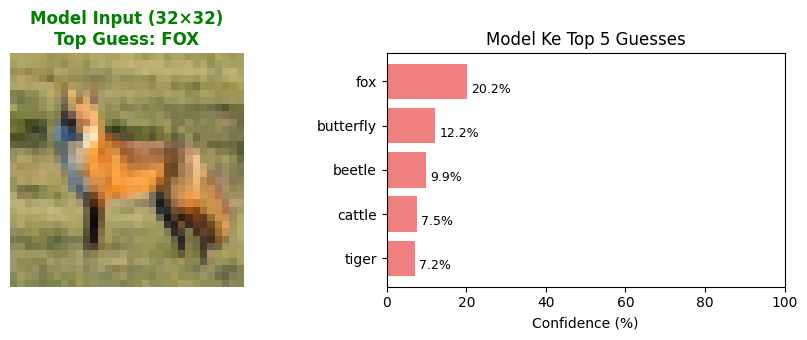

In [47]:
import urllib.request
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# 1. Internet se koi bhi photo download karo (e.g., Red Apple)
# -------------------------------------------------------------
image_url = "https://tse1.mm.bing.net/th/id/OIP.wy5JmII6O52UQvuqqTD4NQHaGR?r=0&rs=1&pid=ImgDetMain&o=7&rm=3"
image_path = "real_world_test.jpg"
urllib.request.urlretrieve(image_url, image_path)

# -------------------------------------------------------------
# 2. Image ko Model ke hisaab se "Pakaana" (Preprocessing)
# -------------------------------------------------------------
# A. Photo open karo aur confirm karo ki 3 channels (RGB) hain
raw_img = Image.open(image_path).convert('RGB')

# B. Photo ko 32x32 pixel me resize karo (Sabse zaroori!)
img_32x32 = raw_img.resize((32, 32))

# C. Pixels ko 0.0 se 1.0 me scale karo
img_array = np.array(img_32x32).astype('float32') / 255.0

# D. 1 Photo ka Batch banao (Shape: 1, 32, 32, 3)
input_tensor = np.expand_dims(img_array, axis=0)

# -------------------------------------------------------------
# 3. Model 2 se Prediction Maango
# -------------------------------------------------------------
predictions = model_2.predict(input_tensor, verbose=0)[0]
top5_indices = np.argsort(predictions)[-5:][::-1]

# -------------------------------------------------------------
# 4. Screen par Photo aur Model ka Faisla Plot Karo!
# -------------------------------------------------------------
plt.figure(figsize=(9, 3.5))

# Left: Real Photo
plt.subplot(1, 2, 1)
plt.imshow(img_32x32)
plt.title(f"Model Input (32×32)\nTop Guess: {cifar100_labels[top5_indices[0]].upper()}",
          fontsize=12, fontweight='bold', color='green')
plt.axis('off')

# Right: Top 5 Bar Chart
plt.subplot(1, 2, 2)
labels = [cifar100_labels[i] for i in reversed(top5_indices)]
scores = [predictions[i] * 100 for i in reversed(top5_indices)]
bars = plt.barh(labels, scores, color='lightcoral')
plt.xlim(0, 100)
plt.xlabel("Confidence (%)")
plt.title("Model Ke Top 5 Guesses")
for bar in bars:
    w = bar.get_width()
    plt.text(w + 1, bar.get_y() + 0.15, f"{w:.1f}%", fontsize=9)

plt.tight_layout()
plt.show()


Center Crop karke bada karte hain taaki background hat jaye aur sirf Seb dikhe

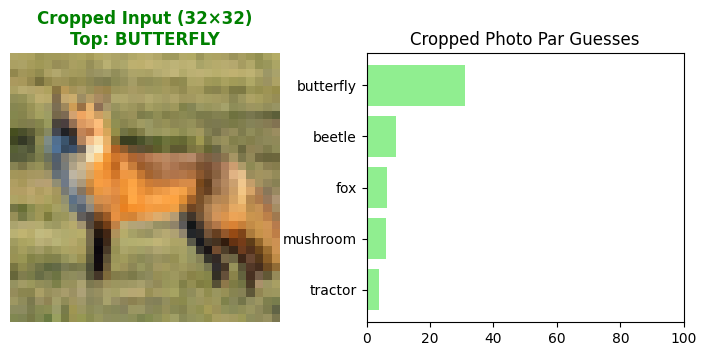

In [48]:
# Seb ko Center Crop karna (Khali background hatana)
w, h = raw_img.size
crop_size = min(w, h)

# Center crop box calculate karna
left = (w - crop_size) // 2
top = (h - crop_size) // 2
right = left + crop_size
bottom = top + crop_size

cropped_img = raw_img.crop((left, top, right, bottom))
cropped_32x32 = cropped_img.resize((32, 32))

# Ab cropped image model ko dete hain
cropped_array = np.array(cropped_32x32).astype('float32') / 255.0
cropped_tensor = np.expand_dims(cropped_array, axis=0)

# Prediction
pred_cropped = model_2.predict(cropped_tensor, verbose=0)[0]
top5_cropped = np.argsort(pred_cropped)[-5:][::-1]

# Plot
plt.figure(figsize=(9, 3.5))

plt.subplot(1, 2, 1)
plt.imshow(cropped_32x32)
plt.title(f"Cropped Input (32×32)\nTop: {cifar100_labels[top5_cropped[0]].upper()}",
          fontsize=12, fontweight='bold', color='green')
plt.axis('off')

plt.subplot(1, 2, 2)
labels = [cifar100_labels[i] for i in reversed(top5_cropped)]
scores = [pred_cropped[i] * 100 for i in reversed(top5_cropped)]
plt.barh(labels, scores, color='lightgreen')
plt.xlim(0, 100)
plt.title("Cropped Photo Par Guesses")
plt.show()
